# Суточный профиль электропотребления и возможные периоды низкой активности

**Вопрос:** как изменяется суточная мощность в течение суток, насколько оценка зависит от пропусков и почему отдельные дни могут иметь низкую нагрузку? Основной период — 2008 год; для контроля сравним другие годы. Важно: измерена **общая активная мощность**, а не отдельно свет. **Пропуски не заполняем** и поездки жильцов не объявляем фактом. Полное описание методов, результатов и инструкция запуска находятся в `README.md`.

## 1. Подготовка окружения и загрузка исходных измерений

В корне проекта выполните `python -m pip install -r requirements.txt` в своем виртуальном окружении. Ноутбук найдет корень проекта, если открыт из `notebooks/`. `?` считается отсутствующим значением; исходный ZIP не изменяется.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise FileNotFoundError('Откройте корневую папку household-energy-profile в VS Code')
sys.path.insert(0,str(ROOT))
from src.analysis import load_raw, audit, clean_year, profiles, run_extended_analysis
raw = load_raw()
print('Всего исходных записей:', len(raw))
print('Временной интервал:', raw.timestamp.min(), '—', raw.timestamp.max())
print('Пустых показаний мощности:', raw.Global_active_power.isna().sum())
display(pd.DataFrame.from_dict(audit(raw),orient='index'))

Matplotlib is building the font cache; this may take a moment.


Всего исходных записей: 2075259
Временной интервал: 2006-12-16 17:24:00 — 2010-11-26 21:02:00
Пустых показаний мощности: 25979


,rows,expected_minutes,absent_timestamps,duplicate_timestamps,missing_power,coverage_pct
2007,525600,525600,0,0,3931,99.25209
2008,527040,527040,0,0,135,99.97439
2009,525600,525600,0,0,4280,99.18569


## 2. Очистка без восстановления данных

Проверяем повторения временных отметок, строки с `?`, невозможные значения и диагностические большие пики. Пики только отмечаются, но не удаляются автоматически: они могут быть реальными.

In [2]:
clean, report = clean_year(raw, 2008)
display(pd.Series(report, name='Показатель'))
assert len(clean) == 526905
assert report['missing_power'] == 135

rows_before                             527040.000
bad_timestamps                               0.000
duplicate_timestamps                         0.000
missing_power                              135.000
physically_invalid_power                     0.000
retained_rows                           526905.000
statistical_high_candidates_retained      3726.000
threshold_3iqr_kw                            5.172
Name: Показатель, dtype: float64

## 3. Три метода расчета суточного профиля

А: среднее по всем доступным минутам; Б: среднее по дням с одинаковым весом; В: только дни со всеми 1 440 минутами. Ни один метод не вставляет недостающие показания.

In [3]:
profile, complete_days, daily_counts = profiles(clean)
print('Полных дней:',complete_days)
display(profile.round(4))

Полных дней: 351


,all_available_kw,equal_day_weight_kw,only_complete_days_kw,minute_observations
hour,,,,
0,0.6309,0.6309,0.6259,21960
1,0.5240,0.5240,0.5178,21960
2,0.4608,0.4608,0.4548,21960
3,0.4468,0.4468,0.4384,21960
4,0.4423,0.4423,0.4347,21960
5,0.4580,0.4580,0.4561,21960
6,0.8061,0.8061,0.8131,21960
7,1.5030,1.5030,1.5033,21960
8,1.4180,1.4180,1.4174,21960


## 4. Построение и сохранение всех графиков

Запускаем единый скрипт анализа. Он записывает таблицы и изображения в `figures/`, **не изменяя исходный ZIP**.

Час максимальной нагрузки: 20
Час минимальной нагрузки: 4


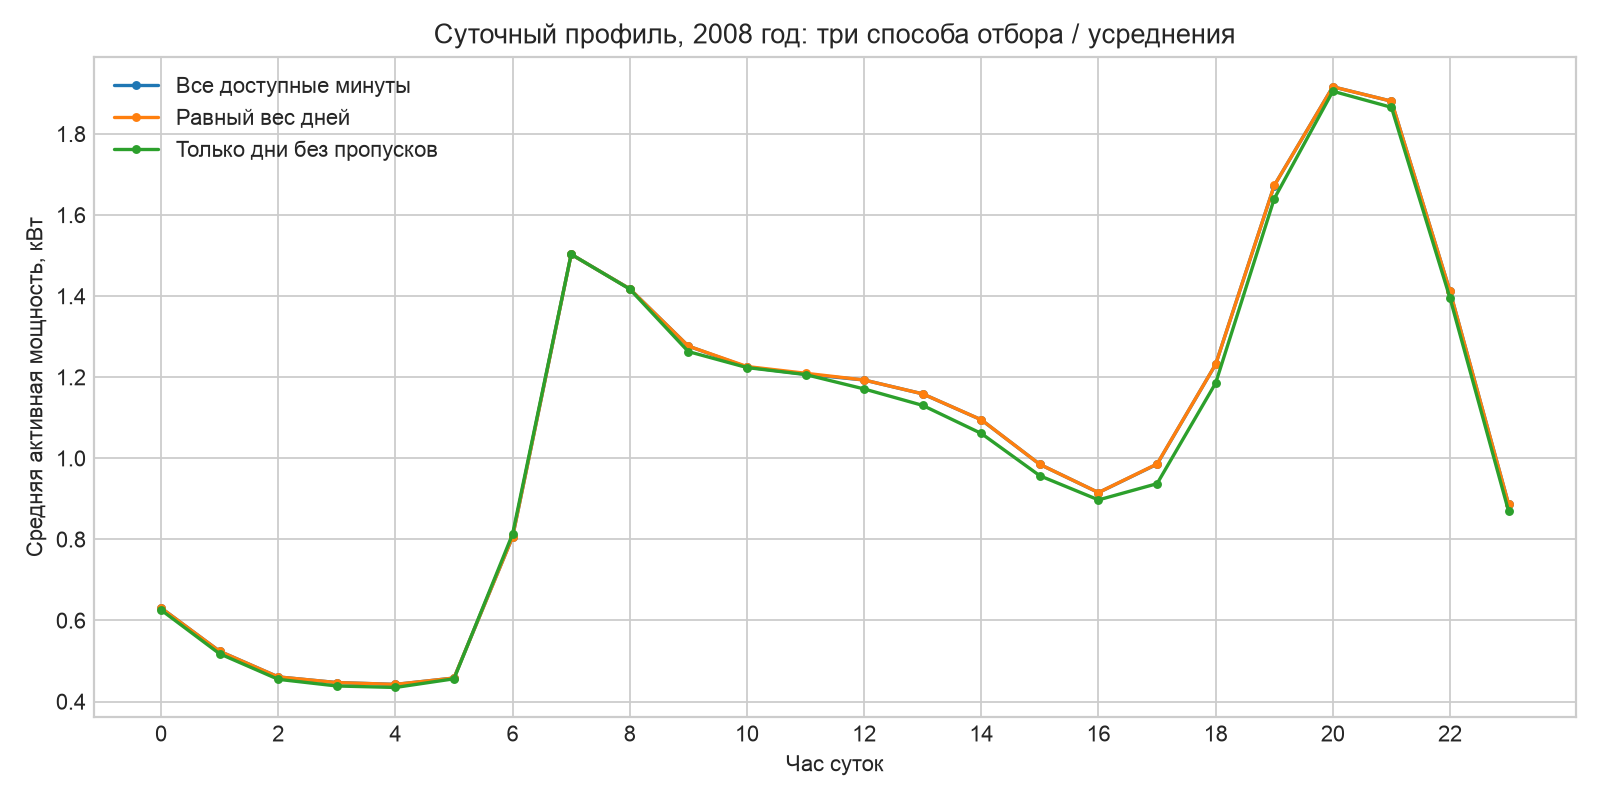

In [4]:
metrics, _, daily, streaks = run_extended_analysis()
print('Час максимальной нагрузки:', metrics['peak_hour'])
print('Час минимальной нагрузки:', metrics['min_hour'])
display(Image(filename=str(ROOT/'figures'/'daily_profiles.png')))

## 5. Сезонность, другие годы и контроль отсутствующих значений

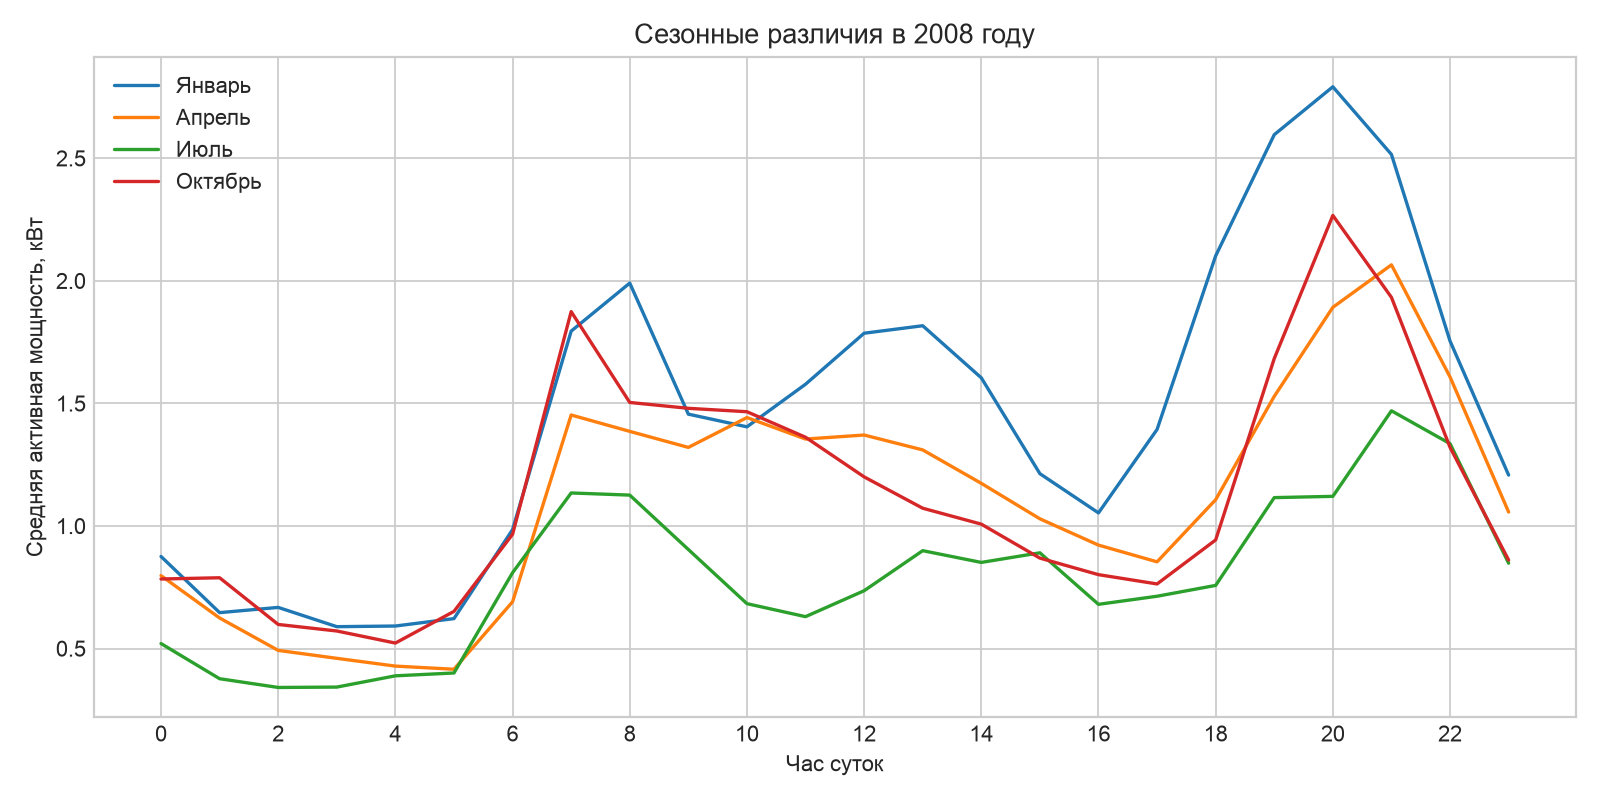

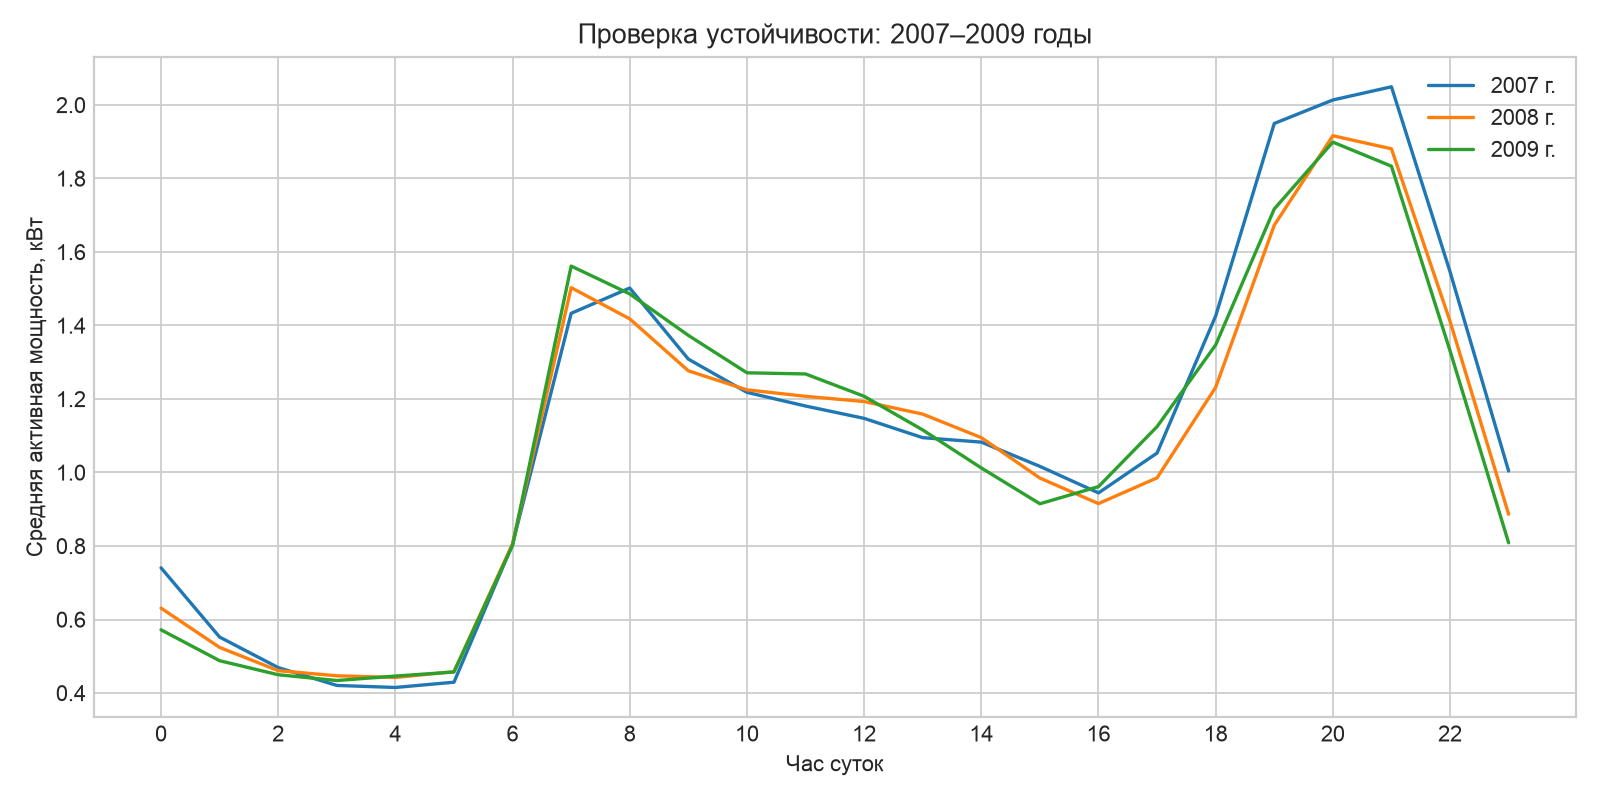

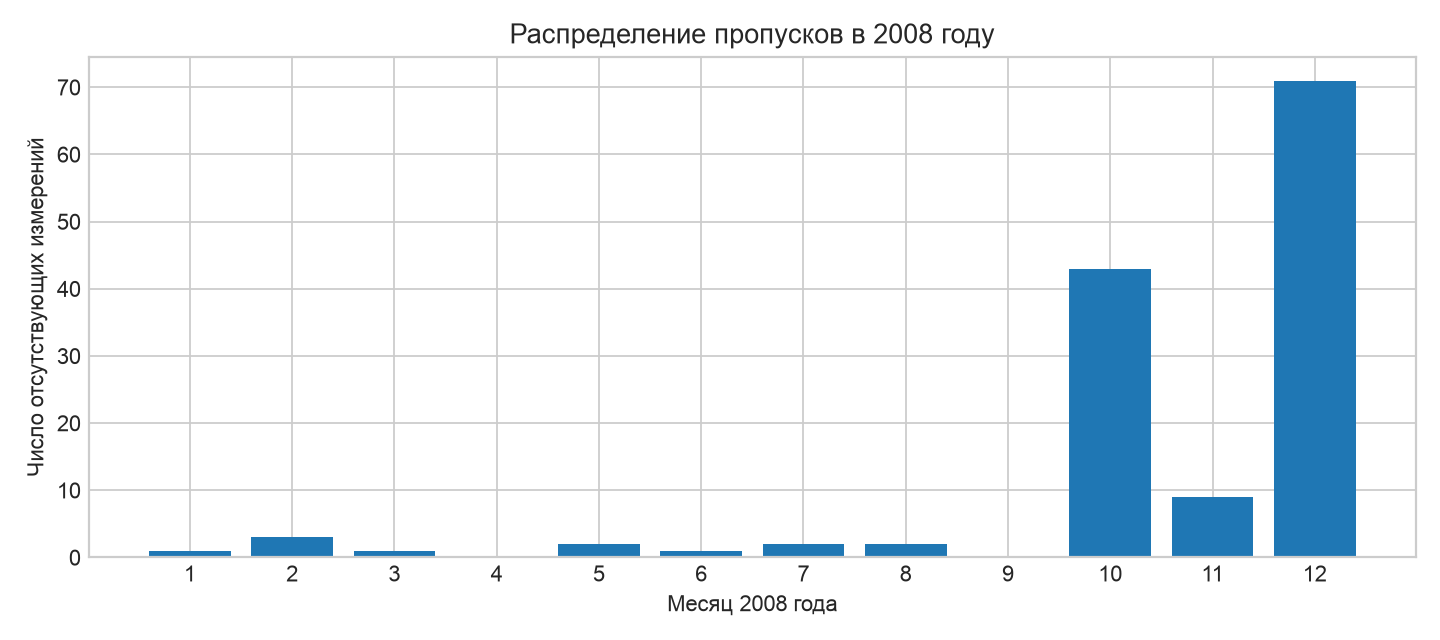

In [5]:
display(Image(filename=str(ROOT/'figures'/'seasonal_profiles.png')))
display(Image(filename=str(ROOT/'figures'/'year_comparison.png')))
display(Image(filename=str(ROOT/'figures'/'missing_by_month.png')))

## 6. Дни необычно низкой мощности

День включается в анализ при покрытии ≥ 95 %. Диагностические критерии: средняя мощность меньше 0,25 кВт либо меньше 65 % медианы по тому же месяцу и дню недели. Это **гипотезы о низкой нагрузке, не о фактическом отъезде**. В частности, август может быть низким по абсолютной шкале и типичным относительно самого августа.

Дней с достаточной полнотой: 366
Дней ниже 0.25 кВт: 24
Дней ниже 65% условного ориентира: 24
Непрерывные периоды:


,start,end,days,mean_kw,minimum_coverage_pct
0,2008-08-12,2008-08-30,19,0.186112,100.0
1,2008-08-06,2008-08-10,5,0.232521,100.0


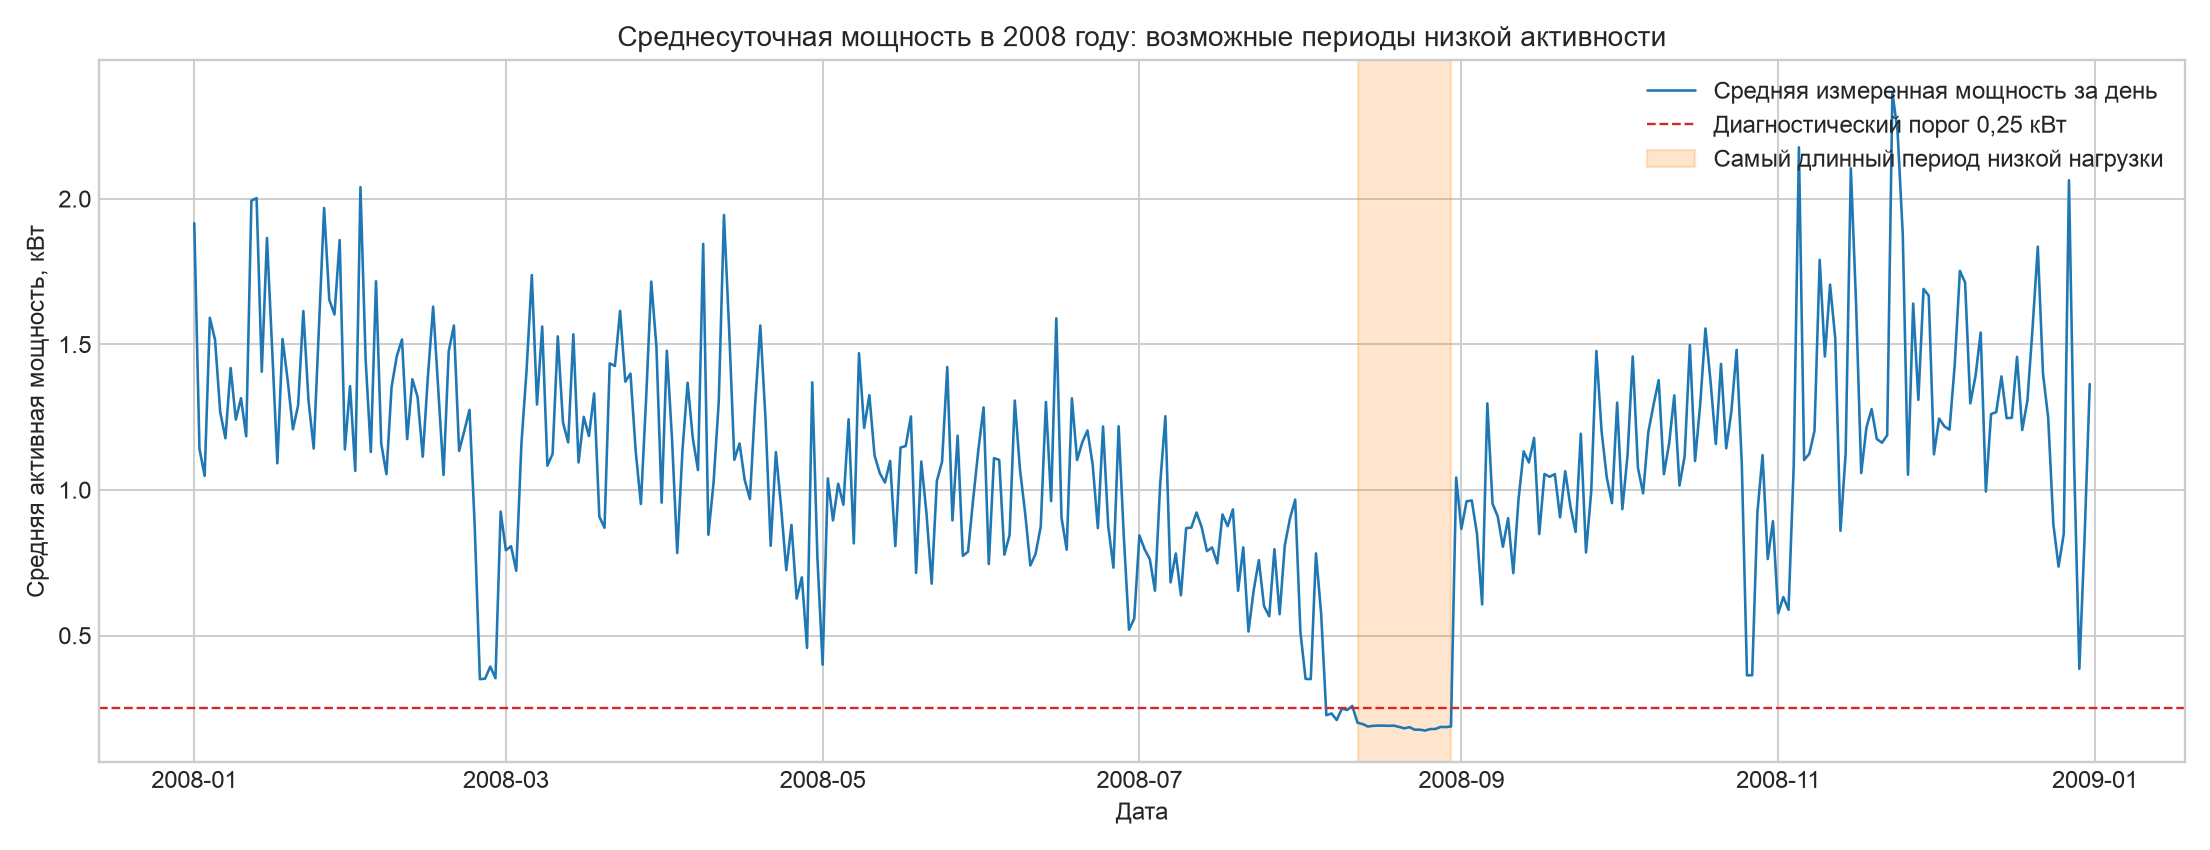

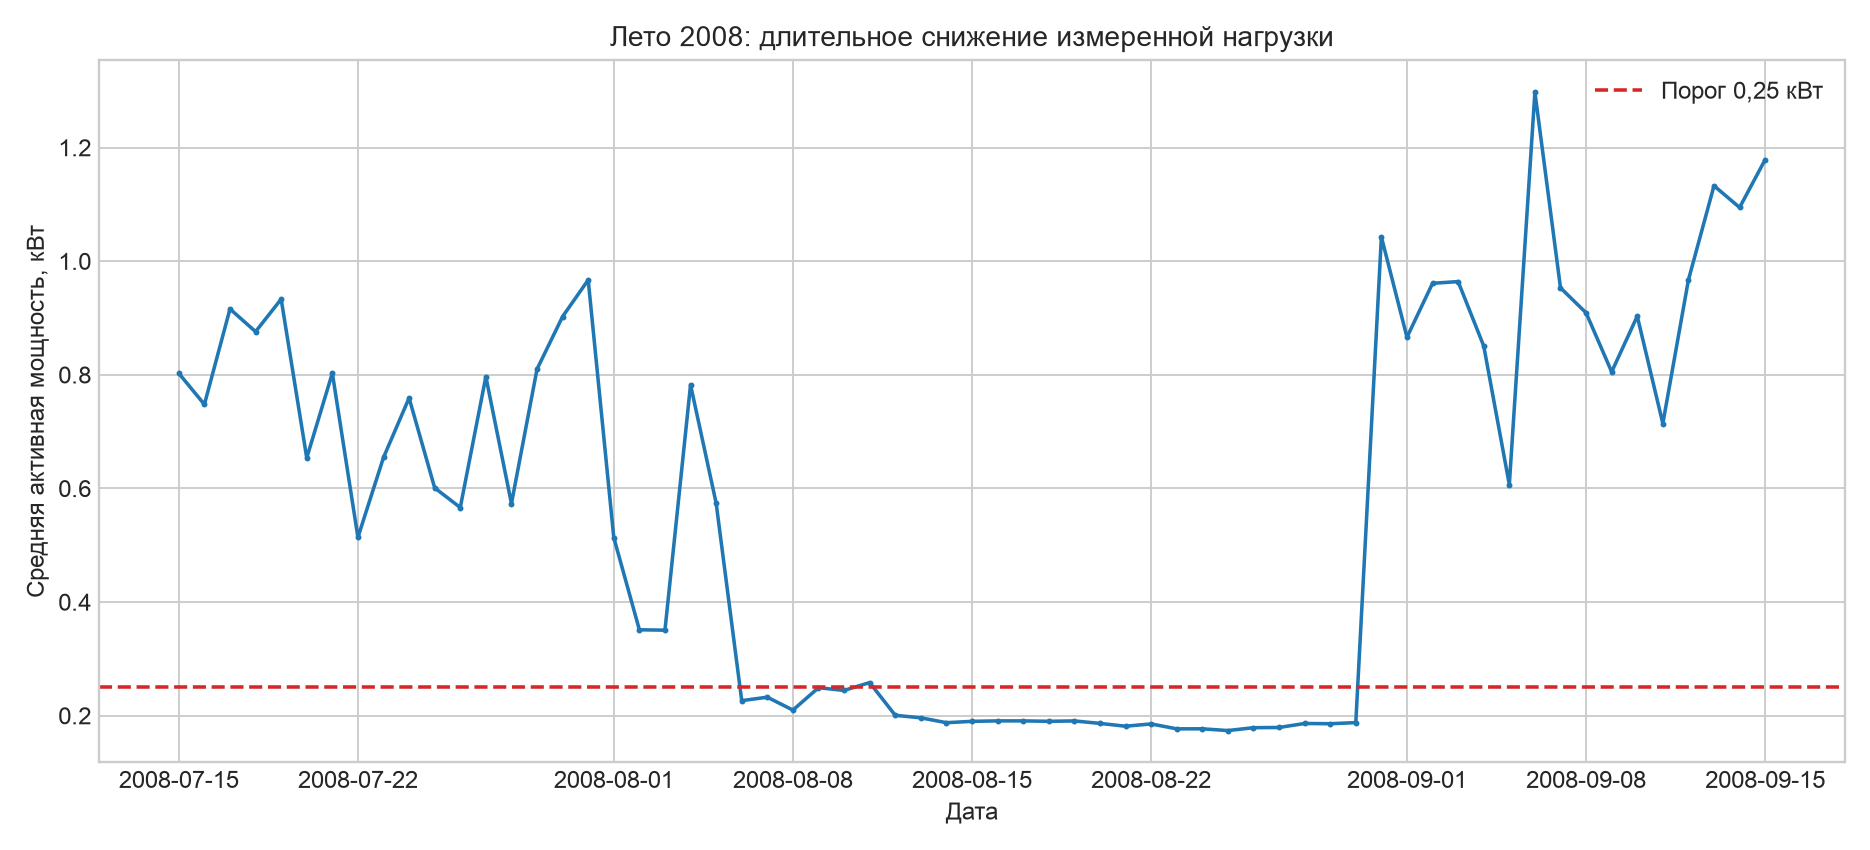

In [6]:
print('Дней с достаточной полнотой:', int(daily.adequate_coverage.sum()))
print('Дней ниже 0.25 кВт:',int(daily.low_absolute.sum()))
print('Дней ниже 65% условного ориентира:',int(daily.low_relative.sum()))
print('Непрерывные периоды:')
display(streaks.head(10))
display(Image(filename=str(ROOT/'figures'/'daily_consumption_timeline.png')))
display(Image(filename=str(ROOT/'figures'/'summer_low_consumption.png')))

## 7. Проверка календарных дат

Сопоставление с датами возможных праздников не доказывает причину поведения. Низкая мощность может отражать отсутствие жильцов, работу приборов в другом режиме и сезонные изменения.

In [7]:
calendar = pd.read_csv(ROOT/'figures'/'calendar_dates_comparison.csv')
display(calendar)
print('На 1 января 2008 года снижения относительно ориентировочных сравнимых дат не обнаружено.')

,date,mean,count,coverage_pct,reference_kw,ratio_to_reference
0,2008-01-01,1.916485,1440,100.0,1.858350,1.031283
1,2008-05-01,0.400010,1440,100.0,0.788247,0.507467
2,2008-07-14,0.790226,1440,100.0,0.736568,1.072849
3,2008-11-11,1.705521,1440,100.0,1.460069,1.168109
4,2008-12-24,0.881693,1440,100.0,1.364019,0.646393
5,2008-12-25,0.736887,1440,100.0,1.100508,0.669589
6,2008-12-26,0.849814,1440,100.0,1.283905,0.661898
7,2008-12-29,0.385610,1440,100.0,1.246840,0.309270
8,2008-12-31,1.364019,1440,100.0,1.364019,1.000000


На 1 января 2008 года снижения относительно ориентировочных сравнимых дат не обнаружено.


## 8. Итоговые выводы

1. Суточный профиль 2008 года имеет минимум около **04:00** и максимум около **20:00**.
2. Исключение неполных дней и выбор способа усреднения меняют величину часовой оценки, но здесь не приводят к радикальному изменению формы.
3. Влияние сезона и года заметно: выбор одного месяца мог бы исказить годовую картину.
4. **12–30 августа 2008 года** наблюдались 19 последовательных дней со среднедневной мощностью меньше 0,25 кВт и полными минутными измерениями. Это наблюдение, но **не подтверждение отпуска жильцов**.
5. Не все потенциально праздничные даты демонстрируют снижение: причина не следует из календаря.

Методика, все численные результаты, ограничения и инструкции установки описаны в `README.md`.